# Intelligence Cup — эластичность спроса

**Цель:** удерживать **только потенциально ценочувствительных клиентов** персональными, окупаемыми предложениями. Без скидок всем подряд.

## 1. Подготовка данных и отбор кандидатов

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

paths = list(Path('.').glob('*.xlsb')) + list(Path('data').glob('*.xlsb')) + list(Path('../data').glob('*.xlsb'))
assert paths, 'Положите исходный .xlsb рядом с ноутбуком или в папку data/'
file_path = str(paths[0])
df = pd.read_excel(file_path, sheet_name='Данные', engine='pyxlsb', header=2)
months = df.columns[3:12].tolist()
df.columns = (['Клиент', 'АЗС_Газпром', 'Топливо']
              + [f'Объем_Газпром_{m}' for m in months]
              + [f'Цена_Газпром_{m}' for m in months]
              + [f'Цена_Конкурент_{m}' for m in months])
print('Клиентов:', len(df), 'Месяцев:', len(months))

Клиентов: 33146 Месяцев: 9


In [2]:
volume_cols = df.columns[3:12].tolist()
volumes = df[volume_cols].apply(pd.to_numeric, errors="coerce")

# Собираем месячные объёмы для расчёта порога по каждому виду топлива
volume_sample = volumes.assign(Топливо=df["Топливо"]).melt(
    id_vars="Топливо",
    value_name="Объем"
)

volume_limits = (
    volume_sample.loc[volume_sample["Объем"] > 0]
    .groupby("Топливо")["Объем"]
    .quantile(0.985) # удаляем все что бльше 1600л
)

limit_by_client = df["Топливо"].map(volume_limits)
is_outlier = volumes.gt(limit_by_client, axis="index")

df_clean = df.copy()
df_clean[volume_cols] = volumes.mask(is_outlier)

display(volume_limits.rename("Порог, л/мес.").round(2))
print("Помечено месячных объёмов:", is_outlier.sum().sum())
print("Затронуто клиентов:", is_outlier.any(axis=1).sum())

Топливо
АИ-92     438.46
АИ-95     386.69
ДТ       1632.49
Name: Порог, л/мес., dtype: float64

Помечено месячных объёмов: 3893
Затронуто клиентов: 1544


In [3]:
tables = []

for month in months:
    month_df = df_clean[["Клиент", "АЗС_Газпром", "Топливо"]].copy()

    month_df["Месяц"] = month
    month_df["Объем"] = df_clean[f"Объем_Газпром_{month}"]
    month_df["Цена_Газпром"] = df_clean[f"Цена_Газпром_{month}"]
    month_df["Цена_Конкурент"] = df_clean[f"Цена_Конкурент_{month}"]

    tables.append(month_df)

client_month = pd.concat(tables, ignore_index=True)

display(client_month[client_month["Клиент"] == "ID_1"])

,Клиент,АЗС_Газпром,Топливо,Месяц,Объем,Цена_Газпром,Цена_Конкурент
0,ID_1,АЗС_926456,АИ-92,2023-09,50.24,49.52,48.86
33146,ID_1,АЗС_926456,АИ-92,2023-10,21.31,49.83,49.12
66292,ID_1,АЗС_926456,АИ-92,2023-11,0.00,50.32,49.53
99438,ID_1,АЗС_926456,АИ-92,2023-12,0.00,51.14,49.79
132584,ID_1,АЗС_926456,АИ-92,2024-01,0.00,51.66,49.82
165730,ID_1,АЗС_926456,АИ-92,2024-02,47.90,52.06,49.82
198876,ID_1,АЗС_926456,АИ-92,2024-03,10.10,52.61,49.82
232022,ID_1,АЗС_926456,АИ-92,2024-04,19.11,52.74,49.87
265168,ID_1,АЗС_926456,АИ-92,2024-05,7.78,52.89,50.32


In [4]:
client_month = client_month.dropna(subset=["Объем"]).copy() # для выбрасов

In [5]:
has_prices = ((client_month["Цена_Газпром"] > 0)  & (client_month["Цена_Конкурент"] > 0))
price_gap = client_month["Цена_Газпром"] - client_month["Цена_Конкурент"]
client_month["Разница_цен"] = price_gap.round(2).where(has_prices)

print("Месяцев без сравнения цен:", client_month["Разница_цен"].isna().sum())
client_month

Месяцев без сравнения цен: 466


,Клиент,АЗС_Газпром,Топливо,Месяц,Объем,Цена_Газпром,Цена_Конкурент,Разница_цен
0,ID_1,АЗС_926456,АИ-92,2023-09,50.24,49.52,48.86,0.66
1,ID_2,АЗС_659322,АИ-95,2023-09,253.51,55.17,55.19,-0.02
2,ID_3,АЗС_431208,АИ-92,2023-09,61.17,53.06,51.31,1.75
3,ID_4,АЗС_1499742,АИ-95,2023-09,8.60,58.11,58.83,-0.72
4,ID_5,АЗС_1082534,АИ-95,2023-09,53.82,56.54,57.57,-1.03
...,...,...,...,...,...,...,...,...
298309,ID_33142,АЗС_1266626,АИ-95,2024-05,25.72,59.15,56.03,3.12
298310,ID_33143,АЗС_557271,АИ-95,2024-05,30.34,59.97,58.17,1.80
298311,ID_33144,АЗС_5118,АИ-95,2024-05,63.82,63.71,60.47,3.24
298312,ID_33145,АЗС_10847,АИ-95,2024-05,180.03,61.70,60.29,1.41


In [6]:
price_months = pd.DataFrame({
    "Клиент": client_month["Клиент"],
    "Газпром_дороже": client_month["Разница_цен"] > 0,
    "Газпром_равно_или_дешевле": client_month["Разница_цен"] <= 0})

client_price_counts = price_months.groupby("Клиент").sum()
can_compare = ( (client_price_counts["Газпром_дороже"] > 0) & (client_price_counts["Газпром_равно_или_дешевле"] > 0))

print("Клиентов всего:", len(client_price_counts))
print("Клиентов с обоими ценовыми условиями:", can_compare.sum())
price_months

Клиентов всего: 33121
Клиентов с обоими ценовыми условиями: 15556


,Клиент,Газпром_дороже,Газпром_равно_или_дешевле
0,ID_1,True,False
1,ID_2,False,True
2,ID_3,True,False
3,ID_4,False,True
4,ID_5,False,True
...,...,...,...
298309,ID_33142,True,False
298310,ID_33143,True,False
298311,ID_33144,True,False
298312,ID_33145,True,False


In [7]:
sensitivity = client_price_counts.loc[can_compare].copy() #берем клиентов только с двумя ценовыми условиями

gap = client_month["Разница_цен"]

avg_expensive = ( client_month.loc[gap > 0].groupby("Клиент")["Объем"].mean()) # ср объем когда Газпром дороже
avg_base = ( client_month.loc[gap <= 0].groupby("Клиент")["Объем"].mean())  # ср объем когда Газпром дешевле или равен
sensitivity["Средний_объем_дороже"] = avg_expensive 
sensitivity["Средний_объем_равно_или_дешевле"] = avg_base

base = sensitivity["Средний_объем_равно_или_дешевле"]
expensive = sensitivity["Средний_объем_дороже"]

sensitivity["Снижение_литров"] = base - expensive
sensitivity["Снижение_проц"] = (base - expensive) / base.where(base > 0) * 100

display(sensitivity.round(2).head())

,Газпром_дороже,Газпром_равно_или_дешевле,Средний_объем_дороже,Средний_объем_равно_или_дешевле,Снижение_литров,Снижение_проц
Клиент,,,,,,
ID_100,5,4,59.11,72.37,13.26,18.32
ID_1000,3,6,81.85,101.68,19.82,19.50
ID_10000,3,6,91.69,93.94,2.25,2.39
ID_10002,5,4,186.24,290.42,104.18,35.87
ID_10004,8,1,116.63,314.81,198.18,62.95


In [8]:
has_multiple_months = ( (sensitivity["Газпром_дороже"] >= 2) & (sensitivity["Газпром_равно_или_дешевле"] >= 2)) # от 2 мес в каждой группе
change = sensitivity.loc[has_multiple_months, "Снижение_литров"].round(2)
print("Клиентов всего (выбранных для данного способа анализа чувствительности):", len(sensitivity))
print("Клиентов с двумя и более месяцами в каждой группе:", len(change))
print("Объём снизился:", (change > 0).sum())
print("Объём совпал:", (change == 0).sum())
print("Объём вырос:", (change < 0).sum())

Клиентов всего (выбранных для данного способа анализа чувствительности): 15556
Клиентов с двумя и более месяцами в каждой группе: 11662
Объём снизился: 8891
Объём совпал: 6
Объём вырос: 2765


In [9]:
decline = sensitivity.loc[has_multiple_months & (change > 0).reindex(sensitivity.index, fill_value=False)].copy()

gap = client_month["Разница_цен"]
max_base = client_month.loc[gap <= 0].groupby("Клиент")["Объем"].max()
min_expensive = client_month.loc[gap > 0].groupby("Клиент")["Объем"].min()

base = decline["Средний_объем_равно_или_дешевле"]
expensive = decline["Средний_объем_дороже"]
n_base = decline["Газпром_равно_или_дешевле"]
n_expensive = decline["Газпром_дороже"]

base_without_max = (base * n_base - max_base.reindex(decline.index)) / (n_base - 1)
expensive_without_min = (
    (expensive * n_expensive - min_expensive.reindex(decline.index))
    / (n_expensive - 1))

decline["Снижение_устойчиво"] = (
    ((base_without_max - expensive).round(2) > 0)
    & ((base - expensive_without_min).round(2) > 0))

print("Клиентов со снижением:", len(decline))
print("Снижение сохраняется при удалении любого одного месяца:", decline["Снижение_устойчиво"].sum())

Клиентов со снижением: 8891
Снижение сохраняется при удалении любого одного месяца: 5045


In [10]:
other_ids = client_price_counts.index[~can_compare] # клиенты 2 способа
other_months = client_month.loc[client_month["Клиент"].isin(other_ids) & client_month["Разница_цен"].notna()].copy() # месяцы этих клиентов с известными ценами
# Делим месяцы каждого клиента на две группы
median_gap = other_months.groupby("Клиент")["Разница_цен"].transform("median") 
other_months["Больший_разрыв"] = other_months["Разница_цен"] > median_gap
gap_counts = (
    other_months.groupby(["Клиент", "Больший_разрыв"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[False, True], fill_value=0))

gap_counts.columns = ["Меньший_разрыв", "Больший_разрыв"]
can_compare_gap = ( (gap_counts["Меньший_разрыв"] >= 2) & (gap_counts["Больший_разрыв"] >= 2))

print("Клиентов с двумя и более месяцами в каждой группе:", can_compare_gap.sum())

Клиентов с двумя и более месяцами в каждой группе:

 16987


In [11]:
avg_gap = (
    other_months.groupby(["Клиент", "Больший_разрыв"])["Разница_цен"]
    .mean()
    .unstack()
    .reindex(columns=[False, True]))

gap_comparison = gap_counts.loc[can_compare_gap].copy()
gap_comparison["Средний_меньший_разрыв"] = avg_gap[False]
gap_comparison["Средний_больший_разрыв"] = avg_gap[True]

gap_comparison["Разница_между_группами"] = (gap_comparison["Средний_больший_разрыв"] - gap_comparison["Средний_меньший_разрыв"]).round(2)

min_gap_change = 0.50 # порог переплаты от 0.5
enough_gap_change = gap_comparison["Разница_между_группами"] >= min_gap_change

print("Клиентов с двумя и более месяцами в каждой группе:", len(gap_comparison))
print("Из них с разницей между группами от 0,50 ₽/л:", enough_gap_change.sum())

Клиентов с двумя и более месяцами в каждой группе: 16987
Из них с разницей между группами от 0,50 ₽/л: 13272


In [12]:
avg_volume = (other_months.groupby(["Клиент", "Больший_разрыв"])["Объем"].mean().unstack())

sensitivity_gap = gap_comparison.loc[enough_gap_change].copy()

sensitivity_gap["Объем_при_меньшем_разрыве"] = avg_volume[False]
sensitivity_gap["Объем_при_большем_разрыве"] = avg_volume[True]

base = sensitivity_gap["Объем_при_меньшем_разрыве"]
worse = sensitivity_gap["Объем_при_большем_разрыве"]

sensitivity_gap["Снижение_литров"] = base - worse
sensitivity_gap["Снижение_проц"] = (base - worse) / base.where(base > 0) * 100

change_gap = sensitivity_gap["Снижение_литров"].round(2)

print("Объём снизился:", (change_gap > 0).sum())
print("Объём совпал:", (change_gap == 0).sum())
print("Объём вырос:", (change_gap < 0).sum())

Объём снизился: 9689
Объём совпал: 6
Объём вырос: 3577


In [13]:
decline_gap = sensitivity_gap.loc[change_gap > 0].copy()

max_base_gap = (other_months.loc[~other_months["Больший_разрыв"]]
    .groupby("Клиент")["Объем"].max().reindex(decline_gap.index))

min_worse_gap = (other_months.loc[other_months["Больший_разрыв"]]
    .groupby("Клиент")["Объем"].min().reindex(decline_gap.index))

base_gap = decline_gap["Объем_при_меньшем_разрыве"]
worse_gap = decline_gap["Объем_при_большем_разрыве"]
n_base_gap = decline_gap["Меньший_разрыв"]
n_worse_gap = decline_gap["Больший_разрыв"]

base_without_max = (base_gap * n_base_gap - max_base_gap) / (n_base_gap - 1)
worse_without_min = (worse_gap * n_worse_gap - min_worse_gap) / (n_worse_gap - 1)

decline_gap["Снижение_устойчиво"] = ( ((base_without_max - worse_gap).round(2) > 0) & ((base_gap - worse_without_min).round(2) > 0))

print("Клиентов со снижением:", len(decline_gap))
print("Из них с устойчивым снижением:", decline_gap["Снижение_устойчиво"].sum())

Клиентов со снижением: 9689
Из них с устойчивым снижением: 5659


In [14]:
columns = ["Снижение_литров", "Снижение_проц"]

stable_first = decline.loc[decline["Снижение_устойчиво"], columns].copy()
stable_first["Способ_оценки"] = "Дороже или равно/дешевле"

stable_second = decline_gap.loc[decline_gap["Снижение_устойчиво"], columns].copy()
stable_second["Способ_оценки"] = "Меньший или больший ценовой разрыв"

segment_base = pd.concat([stable_first, stable_second], verify_integrity=True)

print("Клиентов для сегментации:", len(segment_base))
display(segment_base.head())

Клиентов для сегментации: 10704


,Снижение_литров,Снижение_проц,Способ_оценки
Клиент,,,
ID_100,13.260500,18.322567,Дороже или равно/дешевле
ID_10002,104.181500,35.873010,Дороже или равно/дешевле
ID_10010,85.955000,94.890524,Дороже или равно/дешевле
ID_10014,40.921667,26.143018,Дороже или равно/дешевле
ID_1003,64.735000,100.000000,Дороже или равно/дешевле


В сегментацию попадают клиенты со снижением месячных покупок при менее выгодной относительной цене, которое выдержало проверку исключением одного месяца.  Клиенты с недостаточной историей не получают метку «нечувствительный».

In [15]:
with pd.ExcelFile(file_path, engine="pyxlsb") as excel:
    stations = excel.parse("Информация об АЗС", usecols=["АЗС", "Подразделение"])
    margin = excel.parse("Маржа")
    density = excel.parse("Плотность")

stations = stations.rename(columns={ "АЗС": "АЗС_Газпром", "Подразделение": "Регион"})

client_details = df[["Клиент", "АЗС_Газпром", "Топливо"]].copy()
margin = margin.rename(columns={"НГ": "Топливо"})
density = density.rename(columns={"НГ": "Топливо"})

# Приводим «Аи-92» и «АИ-92» к одному написанию перед объединением
for table in [client_details, margin, density]:
    table["Топливо"] = table["Топливо"].str.strip().str.upper()

segment_economics = (
    segment_base.reset_index()
    .merge(client_details, on="Клиент", how="left", validate="one_to_one")
    .merge(stations, on="АЗС_Газпром", how="left", validate="many_to_one")
    .merge(margin, on=["Регион", "Топливо"], how="left", validate="many_to_one")
    .merge(density, on="Топливо", how="left", validate="many_to_one"))

# из средней маржи в рублях за тонну вычли средний OPEX в рублях за тонну, 
# а затем перевели остаток в рубли за литр через плотность топлива.
segment_economics["Маржа_после_OPEX_руб_л"] = (
    (segment_economics["Средняя маржа, руб/т"] - segment_economics["Средний OPEX, руб/т"])
    * segment_economics["Плотность"] / 1000)

print("Клиентов в таблице:", len(segment_economics))
print("Клиентов без оценки маржи на литр:", segment_economics["Маржа_после_OPEX_руб_л"].isna().sum())

display(segment_economics[["Клиент", "Регион", "Топливо", "Снижение_литров", "Маржа_после_OPEX_руб_л"]].round(2).head())

Клиентов в таблице: 10704
Клиентов без оценки маржи на литр: 0


,Клиент,Регион,Топливо,Снижение_литров,Маржа_после_OPEX_руб_л
0,ID_100,Астана,АИ-95,13.26,9.35
1,ID_10002,Астана,АИ-95,104.18,9.35
2,ID_10010,Астана,АИ-92,85.96,8.90
3,ID_10014,Бишкек,АИ-95,40.92,10.54
4,ID_1003,Астана,АИ-95,64.74,9.35


In [16]:
# Для каждого клиента умножаем наблюдаемое снижение объёма на маржу с одного литра после OPEX. 
# Получаем сколько маржи в месяц мог бы принести этот объём, если бы его удалось удержать целиком
segment_economics["Маржа_на_объём_снижения_руб_мес"] = ( segment_economics["Снижение_литров"] * segment_economics["Маржа_после_OPEX_руб_л"])
columns = ["Клиент","Снижение_литров","Маржа_после_OPEX_руб_л","Маржа_на_объём_снижения_руб_мес"]

segment_economics[columns].sort_values("Маржа_на_объём_снижения_руб_мес", ascending=False).head(10).round(2)

,Клиент,Снижение_литров,Маржа_после_OPEX_руб_л,Маржа_на_объём_снижения_руб_мес
9141,ID_31585,1344.66,12.23,16449.28
10568,ID_934,1305.00,12.23,15964.12
2335,ID_23994,1249.29,12.23,15282.62
1161,ID_16994,967.25,13.22,12785.80
4683,ID_7982,1244.86,9.75,12132.86
10209,ID_7455,907.16,13.22,11991.44
2597,ID_25613,959.99,12.40,11905.00
4746,ID_8298,1142.83,10.06,11499.93
5204,ID_109,1116.17,10.06,11231.63
7327,ID_22134,896.69,12.23,10969.31


In [17]:
value = segment_economics["Маржа_на_объём_снижения_руб_мес"]
positive_value = value[value > 0]

threshold = positive_value.quantile(0.75) # чевтерть 
priority_segment = segment_economics.loc[value >= threshold].copy()

client_share = len(priority_segment) / len(positive_value) * 100
margin_share = value[value >= threshold].sum() / positive_value.sum() * 100

print(f"Граница сегмента: {threshold:.2f} ₽/мес.")
print(f"Клиентов в приоритетном сегменте: {len(priority_segment)}")
print(f"Доля клиентов с положительной оценкой: {client_share:.1f}%")
print(f"Доля оценённой маржи в сегменте: {margin_share:.1f}%")

Граница сегмента: 902.37 ₽/мес.
Клиентов в приоритетном сегменте: 2676
Доля клиентов с положительной оценкой: 25.0%
Доля оценённой маржи в сегменте: 60.0%


Вклад топлива считаем в руб./л как `(средняя маржа − переменный OPEX) × плотность / 1000`. 

## 2. Ценность клиента: топливо и сопутствующие товары

Топливный вклад известен из справочников. По сопутствующим товарам доступна **нетто-выручка с НДС**, но не фактическая прибыль, поэтому **долю вклада магазина задаём сценарно**, а не выдаём выручку за маржу. Уровень бонусной карты сам по себе не подтверждает возможность начисления бонусов. 

In [18]:
ancillary = pd.read_excel(file_path, sheet_name='Покупки сопутствующих товаров', engine='pyxlsb')
ancillary = ancillary.rename(columns={
    'ID_KLIENTA': 'Клиент',
    'Число месяцев с покупками за период анализа': 'Месяцев_СТиУ',
    'Число чеков за период анализа': 'Чеков_СТиУ',
    'Общая выручка по СТиУ Нетто с НДС, руб': 'Выручка_СТиУ_руб'
})
ancillary = ancillary[['Клиент', 'Месяцев_СТиУ', 'Чеков_СТиУ', 'Выручка_СТиУ_руб']]
assert ancillary['Клиент'].is_unique
marketing = segment_economics.merge(ancillary, on='Клиент', how='left', validate='one_to_one')
store_cols = ['Месяцев_СТиУ', 'Чеков_СТиУ', 'Выручка_СТиУ_руб']
marketing[store_cols] = marketing[store_cols].fillna(0)
marketing['Есть_СТиУ'] = marketing['Чеков_СТиУ'] > 0
store_75 = ancillary.loc[ancillary['Выручка_СТиУ_руб'] > 0, 'Выручка_СТиУ_руб'].quantile(0.75)
marketing['Ценный_магазин'] = ((marketing['Выручка_СТиУ_руб'] >= store_75)
                             & (marketing['Месяцев_СТиУ'] >= 3))
marketing['Ценное_топливо'] = marketing['Маржа_на_объём_снижения_руб_мес'] >= threshold
print('Порог высокой выручки СТиУ за период (P75):', round(store_75, 2), '₽')
display(marketing[['Выручка_СТиУ_руб', 'Чеков_СТиУ', 'Месяцев_СТиУ']].describe().round(1))

Порог высокой выручки СТиУ за период (P75): 3192.5 ₽


,Выручка_СТиУ_руб,Чеков_СТиУ,Месяцев_СТиУ
count,10704.0,10704.0,10704.0
mean,1880.9,5.6,2.2
std,5517.2,14.3,2.6
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,258.0,1.0,1.0
75%,1571.5,5.0,4.0
max,192357.5,416.0,9.0


### Канал связи и карта лояльности

- **Push**: приложение + явное согласие на маркетинговый Push.
- **SMS**: если Push недоступен, но есть **SMS-согласие**, отправляем SMS; по вебинару стоимость **10 ₽ за сообщение**.
- **Нет обоих каналов**: дистанционно не связываемся; возможна коммуникация только на кассе, не включённая в расчёт.
- Уровень карты («Серебро», «Золото», «Платина»)  - характеристика, не проверка действительности карты. Перед начислением нужна актуальная проверка POS/CRM.

In [19]:
client_info = pd.read_excel(file_path, sheet_name='Информация о клиентах', engine='pyxlsb')
contact = client_info[[
    'ID_KLIENTA', 'NALICHIE_Mob prilozheniya',
    'SOGLASIE_NA_MARKETINGOVYJ_PUSH', 'SOGLASIE_NA_SMS_RASSYLKU',
    'SOGLASIE_NA_EMAILRASSYLKU', 'STATUS_BONUSNOJ_KARTY'
]].rename(columns={
    'ID_KLIENTA': 'Клиент',
    'NALICHIE_Mob prilozheniya': 'Приложение',
    'SOGLASIE_NA_MARKETINGOVYJ_PUSH': 'Push_согласие',
    'SOGLASIE_NA_SMS_RASSYLKU': 'SMS_согласие',
    'SOGLASIE_NA_EMAILRASSYLKU': 'Email_согласие',
    'STATUS_BONUSNOJ_KARTY': 'Уровень_карты'
})
assert contact['Клиент'].is_unique
marketing = marketing.merge(contact, on='Клиент', how='left', validate='one_to_one')
for col in ['Приложение', 'Push_согласие', 'SMS_согласие', 'Email_согласие']:
    marketing[col] = marketing[col].astype('string').str.strip().str.upper()
marketing['Уровень_карты'] = marketing['Уровень_карты'].astype('string').str.strip().str.title()
marketing['Есть_уровень_карты'] = marketing['Уровень_карты'].isin(['Серебро', 'Золото', 'Платина'])
marketing['Push_доступен'] = (marketing['Приложение'].isin(['Y', '1', '1.0'])
                             & marketing['Push_согласие'].isin(['Y', '1', '1.0']))
marketing['Доступен_пилот'] = marketing['Есть_уровень_карты'] & marketing['Push_доступен']
print('Ценовые кандидаты:', len(marketing))
print('Есть приложение, согласие и известный уровень карты:', int(marketing['Доступен_пилот'].sum()))
display(pd.crosstab(marketing['Уровень_карты'].fillna('Нет сведений'),
                    marketing['Доступен_пилот'], margins=True))

Ценовые кандидаты: 10704
Есть приложение, согласие и известный уровень карты: 6255


Доступен_пилот,False,True,All
Уровень_карты,,,
Золото,1845,2686,4531
Нет сведений,3,0,3
Платина,331,660,991
Серебро,2270,2909,5179
All,4449,6255,10704


In [20]:
formats = pd.read_excel(file_path, sheet_name='Информация об АЗС', engine='pyxlsb',
                        usecols=['АЗС', 'Формат']).rename(columns={'АЗС': 'АЗС_Газпром'})
marketing = marketing.merge(formats, on='АЗС_Газпром', how='left', validate='many_to_one')
marketing['Магазин_возможен'] = marketing['Формат'].isin(['L', 'XL', 'XXL', 'Super-L', 'Super-M'])
marketing['Группа_ценности'] = 'Базовый сегмент'
marketing.loc[marketing['Ценное_топливо'], 'Группа_ценности'] = 'Ценное топливо'
marketing.loc[marketing['Ценный_магазин'], 'Группа_ценности'] = 'Ценный магазин'
marketing.loc[marketing['Ценное_топливо'] & marketing['Ценный_магазин'],
              'Группа_ценности'] = 'Топливо + магазин'
value_groups = marketing.groupby('Группа_ценности').agg(
    Клиентов=('Клиент', 'size'),
    Push_доступен=('Доступен_пилот', 'sum'),
    Медианная_выручка_СТиУ=('Выручка_СТиУ_руб', 'median'),
    Медианный_потенциал_топлива=('Маржа_на_объём_снижения_руб_мес', 'median'))
display(value_groups.round(1))

,Клиентов,Push_доступен,Медианная_выручка_СТиУ,Медианный_потенциал_топлива
Группа_ценности,,,,
Базовый сегмент,7166,3947,0.0,303.1
Топливо + магазин,660,463,6891.5,1608.5
Ценное топливо,2016,1281,349.0,1334.9
Ценный магазин,862,564,6084.0,410.0


## 3. Учитываем реальные пределы роста

Берём исторический **максимум месячного объёма после очистки** как ориентир. Текущее потребление оцениваем как средний объём последних трёх месяцев; это **не точный прогноз без акции**. Максимально возможное восстановление ограничено двумя величинами: (а) выявленным снижением, (б) разницей между историческим максимумом и текущим уровнем.

In [21]:
# База последних 3 месяцев, месячный максимум после очистки
history = client_month.groupby('Клиент')['Объем'].agg(Максимум_литров='max')
recent = client_month[client_month['Месяц'].isin(months[-3:])].groupby('Клиент')['Объем'].mean()
history['База_30д_литры'] = recent
history['Резерв_литры'] = (history['Максимум_литров'] - history['База_30д_литры']).clip(lower=0)

marketing = marketing.merge(history.reset_index(), on='Клиент', how='left', validate='one_to_one')
marketing['Потенциал_возврата_л'] = np.minimum(
    marketing['Снижение_литров'].clip(lower=0), marketing['Резерв_литры'])
last_volume = df_clean.set_index('Клиент')[volume_cols[-1]]
marketing['Ноль_в_последнем_месяце'] = marketing['Клиент'].map(last_volume) == 0
marketing['Поведенческая_группа'] = np.where(
    marketing['Ноль_в_последнем_месяце'], 'Возврат после паузы', 'Удержание')
print('Кандидаты с положительным резервом объёма:', int((marketing['Потенциал_возврата_л'] > 0).sum()))
print('Пауза в покупках за последний месяц:', int(marketing['Ноль_в_последнем_месяце'].sum()))
print('Характеристики групп ценности:')
display(marketing.groupby('Группа_ценности').agg(
    Клиентов=('Клиент', 'size'), Месячный_объём_л=('База_30д_литры', 'sum'),
    Потенциал_возврата_л=('Потенциал_возврата_л', 'sum'),
    Выручка_СТиУ_за_9_мес=('Выручка_СТиУ_руб', 'sum')).round(1))
display(marketing[['Клиент', 'База_30д_литры', 'Максимум_литров',
                   'Снижение_литров', 'Потенциал_возврата_л']].head().round(1))

Кандидаты с положительным резервом объёма: 10701
Пауза в покупках за последний месяц: 3657
Характеристики групп ценности:


,Клиентов,Месячный_объём_л,Потенциал_возврата_л,Выручка_СТиУ_за_9_мес
Группа_ценности,,,,
Базовый сегмент,7166,418198.6,261680.0,3378719.7
Топливо + магазин,660,54647.2,119515.8,7359348.1
Ценное топливо,2016,82520.7,315039.6,1484687.0
Ценный магазин,862,94189.6,36744.0,7910761.8


,Клиент,База_30д_литры,Максимум_литров,Снижение_литров,Потенциал_возврата_л
0,ID_100,48.8,105.0,13.3,13.3
1,ID_10002,190.7,351.2,104.2,104.2
2,ID_10010,0.0,102.8,86.0,86.0
3,ID_10014,140.9,225.6,40.9,40.9
4,ID_1003,0.0,113.7,64.7,64.7


## 4. Каналы, группы и предложения

**Персонализация простыми правилами:** рассматриваем только ценозависимых кандидатов с положительным резервом объёма, маржой и повышенной экономической ценностью. Клиенту, который и так стабильно покупает, ничего не предлагаем.

Для клиентов с исторически высоким вкладом магазина рассматриваем **комбинированное предложение** (топливо + СТиУ), для остальных ценных клиентов — **топливное**. Скидка на топливо ограничена одним месячным лимитом в **12 литров сверх индивидуальной базы**; магазинная часть — фиксированные **15 бонусов** при подтверждённой покупке СТиУ. 

In [22]:
# Разрешённые каналы — только явные согласия
marketing['SMS_доступен'] = marketing['SMS_согласие'].isin(['Y', '1', '1.0'])
marketing['Канал'] = 'Нет дистанционного канала'
marketing.loc[marketing['SMS_доступен'], 'Канал'] = 'SMS'
marketing.loc[marketing['Push_доступен'], 'Канал'] = 'Push'
marketing['Стоимость_контакта_руб'] = np.select(
    [marketing['Канал'] == 'SMS', marketing['Канал'] == 'Push'], [10.0, 0.0], default=0.0)

# Последний известный ценовой разрыв в выгрузке; перед отправкой нужен актуальный
last_gap = client_month.sort_values('Месяц').groupby('Клиент')['Разница_цен'].last()
marketing['Разрыв_последний_руб'] = marketing['Клиент'].map(last_gap)
marketing['Бонус_за_литр'] = np.ceil(marketing['Разрыв_последний_руб'].clip(lower=0))
marketing['Бонус_за_литр'] = marketing['Бонус_за_литр'].where(
    marketing['Бонус_за_литр'].between(1, 3), 0).fillna(0).astype(int)

marketing['Приоритет'] = marketing['Ценное_топливо'] | marketing['Ценный_магазин']
marketing['Механика'] = 'Без бонуса'
ready = (marketing['Приоритет'] & (marketing['Потенциал_возврата_л'] > 0)
         & (marketing['Маржа_после_OPEX_руб_л'] > 0)
         & (marketing['Канал'] != 'Нет дистанционного канала')
         & marketing['Есть_уровень_карты'] & (marketing['Бонус_за_литр'] > 0))
marketing.loc[ready, 'Механика'] = 'Топливное предложение'
combo = ready & marketing['Ценный_магазин'] & marketing['Магазин_возможен']
marketing.loc[combo, 'Механика'] = 'Топливо + СТиУ'
print('Каналы всех ценовых кандидатов:')
display(marketing['Канал'].value_counts().to_frame('Клиентов'))
print('Предварительное распределение механик:')
display(marketing['Механика'].value_counts().to_frame('Клиентов'))

Каналы всех ценовых кандидатов:


,Клиентов
Канал,
Push,6255
SMS,3513
Нет дистанционного канала,936


Предварительное распределение механик:


,Клиентов
Механика,
Без бонуса,8632
Топливное предложение,1612
Топливо + СТиУ,460


## 5. Сценарный экономический эффект («Было - Стало»)

Чтобы не рисовать дополнительные продажи произвольно, у каждого выбранного клиента возможный прирост литров ограничен **наблюдаемым резервом**. Для сценария используем только **долю** этого резерва, а не весь максимум. Если бонус получен за обычную покупку без прироста, это **расход**, а не успех акции.

**Параметры, которых нет в выгрузке (допущения):** дополнительный отклик на бонус 1/2/3, доля начисления бонусов, доля возмещаемого исторического объёма, вклад СТиУ и реальная стоимость одного бонуса. Ни один не выведен из эксперимента. В расчёте 1 бонус = 1 ₽ расхода — только консервативная рабочая гипотеза, которую нужно согласовать с компанией.

**Топливо:** инкрементальные литры × (маржа − переменный OPEX) на литр. **Магазин:** только дополнительная выручка × предположенный вклад. **Затраты:** бонус/л только на литры сверх персональной среднемесячной базы (с лимитом и POS-проверкой) + фиксированный бонус СТиУ + платная SMS. Даже без реального прироста некоторые клиенты могут естественно превысить базу и получить бонус — это отражает `redeem_rate`. В прошлом периоде скидок нет. Регионы — **условные категории справочника с разными финансовыми нормативами**, не реальные рынки со своими валютами.

In [23]:
# Прозрачные допущения для пилота (можно менять)
bonus_cost = 1.0                 # ₽ на 1 бонус, гипотеза
store_contribution = 0.20        # доля вклада от нетто-выручки СТиУ с НДС, гипотеза
store_bonus = 15.0              # бонусы за подтверждённую покупку СТиУ
liters_limit = 12.0             # лимит премируемых литров сверх персональной базы

scenarios = [
    {'Сценарий': 'Без прироста', 'recover_share': 0.0, 'increment_rate': 0.0,
     'redeem_rate': 0.25, 'extra_store': 0.0},
    {'Сценарий': 'Осторожный', 'recover_share': 0.15, 'increment_rate': 0.06,
     'redeem_rate': 0.23, 'extra_store': 40.0},
    {'Сценарий': 'Рабочий', 'recover_share': 0.35, 'increment_rate': 0.15,
     'redeem_rate': 0.30, 'extra_store': 100.0},
    {'Сценарий': 'Сильный', 'recover_share': 0.50, 'increment_rate': 0.25,
     'redeem_rate': 0.40, 'extra_store': 150.0},
]
# Отклик на 1/2/3 бонуса/л: только гипотеза, а не предсказанные вероятности
rate_factor = {0: 0.0, 1: 0.65, 2: 0.85, 3: 1.0}

campaign = marketing.loc[ready].copy()
campaign['Комбо'] = campaign['Механика'] == 'Топливо + СТиУ'
print('Доступны для условного пилота:', len(campaign))
print('Подгруппы удержания и возврата:')
display(pd.crosstab(campaign['Поведенческая_группа'], campaign['Механика']))
display(campaign.groupby(['Канал', 'Механика']).agg(
    Клиентов=('Клиент', 'size'), Медиана_резерва_л=('Потенциал_возврата_л', 'median'),
    Медиана_СТиУ_руб=('Выручка_СТиУ_руб', 'median')).round(1))

Доступны для условного пилота: 2072
Подгруппы удержания и возврата:


Механика,Топливное предложение,Топливо + СТиУ
Поведенческая_группа,,
Возврат после паузы,825,144
Удержание,787,316


Клиентов  Медиана_резерва_л  Медиана_СТиУ_руб
Канал Механика                                                            
Push  Топливное предложение      1135              131.5             881.0
      Топливо + СТиУ              332               72.4            6796.0
SMS   Топливное предложение       477              129.3             587.0
      Топливо + СТиУ              128               66.5            6209.0

In [24]:
# Для каждой стратегии и сценария считаем результат каждого клиента.
results = []
for s in scenarios:
    x = campaign.copy()
    x['Вероятность_доп_покупки'] = s['increment_rate'] * x['Бонус_за_литр'].map(rate_factor)
    x['Литры_при_отклике'] = np.minimum(12, x['Потенциал_возврата_л'] * s['recover_share'])
    x['Доп_литры'] = x['Вероятность_доп_покупки'] * x['Литры_при_отклике']
    x['Доп_топливо_руб'] = x['Доп_литры'] * x['Маржа_после_OPEX_руб_л']
    x['Доп_СТиУ_руб'] = (x['Комбо'] * x['Вероятность_доп_покупки']
                          * s['extra_store'] * store_contribution)
    # Бонус получают и некоторые клиенты, не увеличившие покупки.
    # Только литры СВЕРХ персональной базы, но лимит персонального резерва.
    # Расход возможен и без инкрементального эффекта — из-за обычных колебаний спроса.
    x['Расход_бонусов_руб'] = (s['redeem_rate'] * bonus_cost *
        (x['Бонус_за_литр'] * np.minimum(liters_limit, 0.35 * x['Потенциал_возврата_л'])
         + x['Комбо'] * store_bonus))
    x['Расход_связи_руб'] = x['Стоимость_контакта_руб']
    x['Эффект_руб'] = (x['Доп_топливо_руб'] + x['Доп_СТиУ_руб']
                       - x['Расход_бонусов_руб'] - x['Расход_связи_руб'])
    x['Сценарий'] = s['Сценарий']
    results.append(x)
campaign_scenarios = pd.concat(results, ignore_index=True)

scenario_totals = campaign_scenarios.groupby('Сценарий').agg(
    Клиентов=('Клиент', 'size'), Доп_литры=('Доп_литры', 'sum'),
    Топливо_руб=('Доп_топливо_руб', 'sum'), Магазин_руб=('Доп_СТиУ_руб', 'sum'),
    Бонусы_руб=('Расход_бонусов_руб', 'sum'), SMS_и_Push_руб=('Расход_связи_руб', 'sum'),
    Чистый_эффект_руб=('Эффект_руб', 'sum')).reindex([s['Сценарий'] for s in scenarios])
display(scenario_totals.round(1))

,Клиентов,Доп_литры,Топливо_руб,Магазин_руб,Бонусы_руб,SMS_и_Push_руб,Чистый_эффект_руб
Сценарий,,,,,,,
Без прироста,2072,0.0,0.0,0.0,13899.8,6050.0,-19949.8
Осторожный,2072,1116.9,11077.9,186.2,12787.8,6050.0,-7573.6
Рабочий,2072,3022.5,30011.1,1164.0,16679.8,6050.0,8445.3
Сильный,2072,5131.6,50963.1,2910.0,22239.7,6050.0,25583.4


### Проверка экономики и персональный отказ от невыгодного оффера

Две версии: **всем предварительно доступным кандидатам** и **только тем, у кого в выбранном сценарии ожидаемая дополнительная прибыль после расходов положительна**. Это простое правило и является оптимизацией затрат, **но подтверждение реального отклика всё равно требует A/B-теста**. Если условия у клиента невыгодные — **0 бонусов** и нет SMS/Push-акции.

In [25]:
working = campaign_scenarios[campaign_scenarios['Сценарий'] == 'Рабочий'].copy()
selected_ids = working.loc[working['Эффект_руб'] > 0, 'Клиент']
selected = campaign_scenarios[campaign_scenarios['Клиент'].isin(selected_ids)].copy()
print('Клиентов с положительным сценарным эффектом:', len(selected_ids))
selected_totals = selected.groupby('Сценарий')[
    ['Доп_литры', 'Доп_топливо_руб', 'Доп_СТиУ_руб',
     'Расход_бонусов_руб', 'Расход_связи_руб', 'Эффект_руб']
].sum().reindex([s['Сценарий'] for s in scenarios])
display(selected_totals.round(1))

# Региональный результат для одной и той же аудитории и 30-дневного периода
base = campaign[campaign['Клиент'].isin(selected_ids)].copy()
base['Было_руб'] = (base['База_30д_литры'] * base['Маржа_после_OPEX_руб_л']
                    + base['Выручка_СТиУ_руб'] / 9 * store_contribution)
regional = selected.groupby(['Сценарий', 'Регион']).agg(
    Клиентов=('Клиент', 'size'), Доп_литры=('Доп_литры', 'sum'),
    Доп_топливо_руб=('Доп_топливо_руб', 'sum'), Доп_СТиУ_руб=('Доп_СТиУ_руб', 'sum'),
    Бонусы_руб=('Расход_бонусов_руб', 'sum'), Связь_руб=('Расход_связи_руб', 'sum'),
    Эффект_руб=('Эффект_руб', 'sum')).reset_index()
regional = regional.merge(base.groupby('Регион')['Было_руб'].sum().rename('Было_руб'),
                          on='Регион', how='left', validate='many_to_one')
regional['Стало_руб'] = regional['Было_руб'] + regional['Эффект_руб']
print('Было → Стало по регионам, рабочий сценарий:')
display(regional[regional['Сценарий'] == 'Рабочий'].sort_values('Эффект_руб', ascending=False).round(1))

Клиентов с положительным сценарным эффектом: 1522


,Доп_литры,Доп_топливо_руб,Доп_СТиУ_руб,Расход_бонусов_руб,Расход_связи_руб,Эффект_руб
Сценарий,,,,,,
Без прироста,0.0,0.0,0.0,10265.8,620.0,-10885.8
Осторожный,828.4,8274.8,132.7,9444.6,620.0,-1657.0
Рабочий,2240.7,22390.2,829.5,12319.0,620.0,10280.7
Сильный,3797.9,37947.9,2073.8,16425.3,620.0,22976.3


Было → Стало по регионам, рабочий сценарий:


,Сценарий,Регион,Клиентов,Доп_литры,Доп_топливо_руб,Доп_СТиУ_руб,Бонусы_руб,Связь_руб,Эффект_руб,Было_руб,Стало_руб
22,Рабочий,Астана,479,728.9,6712.2,107.2,3832.9,0.0,2986.5,210218.7,213205.2
25,Рабочий,Бишкек,318,438.9,4625.6,256.4,2429.1,110.0,2342.8,276097.1,278439.9
27,Рабочий,Ереван,143,227.0,2493.2,80.9,1360.0,60.0,1154.1,107570.0,108724.1
32,Рабочий,Ташкент,151,223.0,2463.6,51.0,1157.6,240.0,1117.0,93976.9,95093.9
30,Рабочий,Москва,148,199.3,2033.2,129.0,1111.6,60.0,990.6,101353.3,102343.9
31,Рабочий,Пекин,142,205.2,2043.5,65.9,1065.3,80.0,964.1,112745.0,113709.1
29,Рабочий,Минск,71,105.7,1037.9,102.4,699.8,30.0,410.5,52727.4,53137.9
23,Рабочий,Ашхабад,55,89.8,749.9,31.6,542.1,0.0,239.4,24835.6,25075.0
24,Рабочий,Баку,7,11.2,102.3,5.1,66.6,10.0,30.8,14916.3,14947.1
28,Рабочий,Кишинев,4,5.9,58.3,0.0,28.8,0.0,29.5,8951.7,8981.2


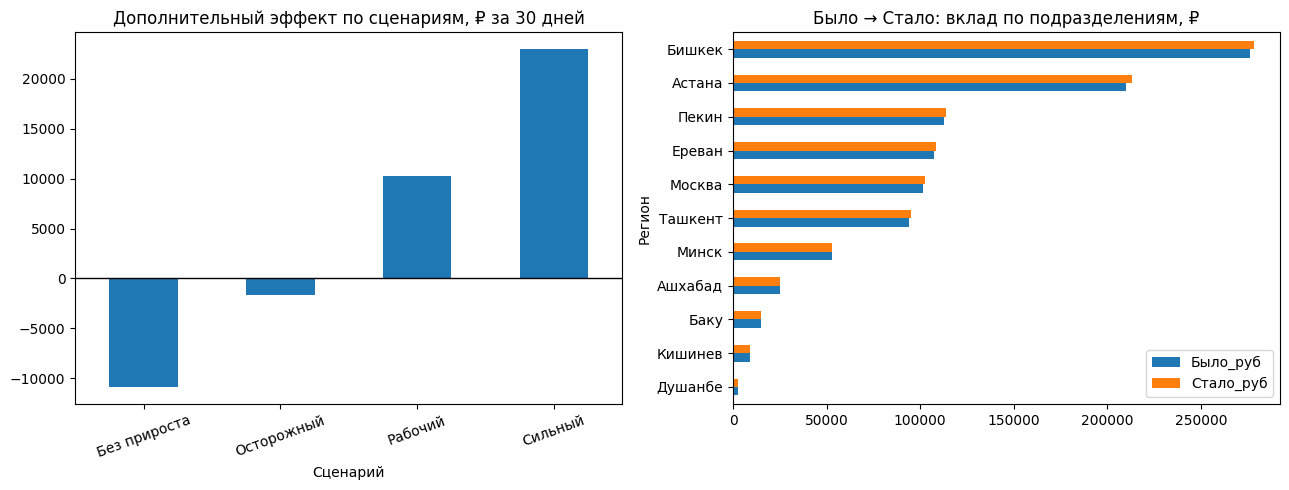

In [26]:
# Визуализация результатов
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
selected_totals['Эффект_руб'].plot.bar(ax=axes[0])
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Дополнительный эффект по сценариям, ₽ за 30 дней')
axes[0].tick_params(axis='x', rotation=20)
w = regional[regional['Сценарий'] == 'Рабочий'].set_index('Регион')
w[['Было_руб', 'Стало_руб']].sort_values('Было_руб').plot.barh(ax=axes[1])
axes[1].set_title('Было → Стало: вклад по подразделениям, ₽')
plt.tight_layout()
plt.show()